# 02 - Calidad ESIOS: raw -> processed

Este notebook valida y transforma la ingesta raw de ESIOS sin volver a llamar a la API.
Los bloques vacíos se conservan y se diagnostican: no se convierten en ceros ni se descartan silenciosamente.

La salida normalizada es una capa silver trazable a cada archivo raw y a cada bloque solicitado.

In [15]:
import json
import re
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv


def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "requirements.txt").is_file() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto.")


PROJECT_ROOT = find_project_root()
load_dotenv(PROJECT_ROOT / ".env")
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "esios"
OUT_DIR = PROJECT_ROOT / "data" / "processed" / "esios"
CATALOG_PATH = PROJECT_ROOT / "docs" / "fuentes" / "esios" / "catalogo_indicadores_esios.csv"
START_DATE = pd.Timestamp("2024-10-01", tz="UTC")
END_DATE = pd.Timestamp("2026-09-30 23:59:59", tz="UTC")
INDICATOR_IDS = [28, 29, 30, 31, 32, 33, 34, 35, 460, 462, 472, 473, 474, 475, 476, 477, 478, 479, 506, 507, 1844, 1845, 1846, 1848, 1849, 1850, 541, 542, 543, 545, 603, 546, 547, 549, 551, 552, 1297, 2041, 2051, 570, 623, 628]
FILE_PATTERN = re.compile(r"indicador_(?P<id>\d+)_(?P<start>\d{4}-\d{2}-\d{2})_(?P<end>\d{4}-\d{2}-\d{2})\.json$")

print(f"Raíz: {PROJECT_ROOT}")
print(f"Raw ESIOS: {RAW_DIR}")
print(f"Ventana de calidad: {START_DATE} a {END_DATE}")

Raíz: c:\Users\zhen.xiang\OneDrive - Accenture\Documents\SAT\Energy\odb-challenge-energy-optimizer
Raw ESIOS: c:\Users\zhen.xiang\OneDrive - Accenture\Documents\SAT\Energy\odb-challenge-energy-optimizer\data\raw\esios
Ventana de calidad: 2024-10-01 00:00:00+00:00 a 2026-09-30 23:59:59+00:00


## 1. Configuración y alcance

Este notebook solo lee archivos locales. No descarga datos ni modifica la capa raw.

## 2. Catálogo e indicadores seleccionados

In [16]:
if not CATALOG_PATH.exists():
    raise FileNotFoundError(f"No existe el catálogo guardado: {CATALOG_PATH}")

catalog = pd.read_csv(CATALOG_PATH)
catalog["id"] = pd.to_numeric(catalog["id"], errors="coerce").astype("Int64")
selected_catalog = catalog[catalog["id"].isin(INDICATOR_IDS)].copy()
missing_ids = sorted(set(INDICATOR_IDS) - set(selected_catalog["id"].dropna().astype(int)))
if missing_ids:
    raise ValueError(f"Indicadores seleccionados ausentes del catálogo: {missing_ids}")

selected_catalog = selected_catalog.rename(columns={"id": "indicator_id", "name": "indicator_name"})
for column in ("short_name", "description", "publication"):
    if column not in selected_catalog:
        selected_catalog[column] = pd.NA
selected_catalog["unit"] = pd.NA
selected_catalog["frequency"] = pd.NA
selected_catalog[["indicator_id", "indicator_name", "short_name", "unit", "frequency", "description", "publication"]]

,indicator_id,indicator_name,short_name,unit,frequency,description,publication
27,28,Generación programada PBF Importación Francia,Importación Francia,<NA>,<NA>,"Es el programa de energía diario, con desglose...",diariamente a partir de las 13:45 horas con la...
28,29,Generación programada PBF Importación Portugal,Importación Portugal,<NA>,<NA>,"Es el programa de energía diario, con desglose...",diariamente a partir de las 13:45 horas con la...
29,30,Generación programada PBF Importación Marruecos,Importación Marruecos,<NA>,<NA>,"Es el programa de energía diario, con desglose...",diariamente a partir de las 13:45 horas con la...
30,31,Generación programada PBF Importación Andorra,Importación Andorra,<NA>,<NA>,"Es el programa de energía diario, con desglose...",diariamente a partir de las 13:45 horas con la...
31,32,Generación programada PBF Exportación Francia,Exportación Francia,<NA>,<NA>,"Es el programa de energía diario, con desglose...",diariamente a partir de las 13:45 horas con la...
32,33,Generación programada PBF Exportación Portugal,Exportación Portugal,<NA>,<NA>,"Es el programa de energía diario, con desglose...",diariamente a partir de las 13:45 horas con la...
33,34,Generación programada PBF Exportación Marruecos,Exportación Marruecos,<NA>,<NA>,"Es el programa de energía diario, con desglose...",diariamente a partir de las 13:45 horas con la...
34,35,Generación programada PBF Exportación Andorra,Exportación Andorra,<NA>,<NA>,"Es el programa de energía diario, con desglose...",diariamente a partir de las 13:45 horas con la...
459,460,Previsión diaria de la demanda eléctrica penin...,Previsión diaria,<NA>,<NA>,Es la previsión de consumo que Red Eléctrica e...,diariamente se actualiza la previsión del día ...
461,462,Potencia indisponible de generación en PBF,Indisponible,<NA>,<NA>,Suma total de indisponibilidades de potencia a...,en el día D una vez publicado el programa diario.


## 3. Lectura raw y clasificación de bloques

Un bloque `empty` es una respuesta válida con `indicator.values` vacío. Se conserva en el diagnóstico y no se convierte en cero.

In [17]:
def metadata_text(indicator: dict, key: str) -> str | None:
    items = indicator.get(key)
    if not isinstance(items, list):
        return None
    names = [item.get("name") for item in items if isinstance(item, dict) and item.get("name")]
    return "; ".join(map(str, names)) or None


def classify_file(path: Path) -> dict:
    match = FILE_PATTERN.fullmatch(path.name)
    result = {
        "source_file": str(path.relative_to(PROJECT_ROOT)),
        "file_name": path.name,
        "file_size_bytes": path.stat().st_size,
        "indicator_id": int(match.group("id")) if match else None,
        "requested_start": match.group("start") if match else None,
        "requested_end": match.group("end") if match else None,
        "status": "malformed",
        "value_count": 0,
        "indicator_name": None,
        "unit": None,
        "frequency": None,
        "payload": None,
        "error": None,
    }
    if not match:
        result["error"] = "Nombre de archivo no reconocido"
        return result
    try:
        payload = json.loads(path.read_text(encoding="utf-8"))
    except (OSError, UnicodeDecodeError, json.JSONDecodeError) as exc:
        result["status"] = "unreadable"
        result["error"] = str(exc)
        return result
    indicator = payload.get("indicator") if isinstance(payload, dict) else None
    values = indicator.get("values") if isinstance(indicator, dict) else None
    if not isinstance(indicator, dict) or not isinstance(values, list):
        result["error"] = "Falta indicator.values como lista"
        return result
    result.update({
        "status": "empty" if not values else "valid",
        "value_count": len(values),
        "indicator_name": indicator.get("name"),
        "unit": metadata_text(indicator, "magnitud"),
        "frequency": metadata_text(indicator, "tiempo"),
        "payload": payload,
    })
    return result


all_raw_files = sorted((RAW_DIR / "indicadores").glob("*/indicador_*.json"))
raw_files = [
    path for path in all_raw_files
    if path.parent.name.isdigit() and int(path.parent.name) in INDICATOR_IDS
]
if not raw_files:
    raise FileNotFoundError(f"No hay archivos raw para los indicadores seleccionados en {RAW_DIR / 'indicadores'}")

print(f"Archivos raw encontrados: {len(all_raw_files):,}")
print(f"Archivos raw de indicadores seleccionados: {len(raw_files):,}")
block_records = [classify_file(path) for path in raw_files]
blocks = pd.DataFrame([{k: v for k, v in record.items() if k != "payload"} for record in block_records])
blocks["indicator_id"] = pd.to_numeric(blocks["indicator_id"], errors="coerce").astype("Int64")
blocks["requested_start"] = pd.to_datetime(blocks["requested_start"], utc=True, errors="coerce")
blocks["requested_end"] = pd.to_datetime(blocks["requested_end"], utc=True, errors="coerce")
blocks["requested_days"] = (blocks["requested_end"] - blocks["requested_start"]).dt.days + 1
blocks["in_configured_window"] = (blocks["requested_end"] >= START_DATE) & (blocks["requested_start"] <= END_DATE)
blocks["status"].value_counts(dropna=False)

Archivos raw encontrados: 6,065
Archivos raw de indicadores seleccionados: 1,186


status
valid    1090
empty      96
Name: count, dtype: int64

## 4. Diagnóstico de bloques vacíos

Los vacíos se revisan por indicador, mes, año y rango solicitado. Un vacío persistente de un indicador puede ser falta real de publicación o un indicador/granularidad inadecuados; no se rellena automáticamente.

In [18]:
empty_blocks = blocks[blocks["status"] == "empty"].copy()
empty_blocks["requested_month"] = empty_blocks["requested_start"].dt.to_period("M").astype("string")
empty_blocks["requested_year"] = empty_blocks["requested_start"].dt.year.astype("Int64")
empty_by_indicator = empty_blocks.groupby(["indicator_id", "indicator_name", "frequency"], dropna=False).size().reset_index(name="empty_blocks")
empty_by_month = empty_blocks.groupby("requested_month", dropna=False).size().reset_index(name="empty_blocks")
empty_by_year = empty_blocks.groupby("requested_year", dropna=False).size().reset_index(name="empty_blocks")
empty_detail = empty_blocks[[
    "source_file", "indicator_id", "indicator_name", "unit", "frequency",
    "requested_start", "requested_end", "requested_days", "file_size_bytes", "error",
]].sort_values(["indicator_id", "requested_start"])

block_summary = blocks.pivot_table(
    index=["indicator_id", "indicator_name"],
    columns="status",
    values="file_name",
    aggfunc="count",
    fill_value=0,
).reset_index()
for column in ("valid", "empty", "malformed", "unreadable"):
    if column not in block_summary:
        block_summary[column] = 0
all_empty_indicators = block_summary[
    (block_summary["empty"] > 0) & (block_summary["valid"] == 0)
].sort_values("indicator_id")

print(f"Bloques vacíos: {len(empty_detail)}")
print("Indicadores con todos sus bloques vacíos:")
print(all_empty_indicators.to_string(index=False))
print("\nBloques vacíos por indicador:")
empty_by_indicator

Bloques vacíos: 96
Indicadores con todos sus bloques vacíos:
 indicator_id                                indicator_name  empty  valid  malformed  unreadable
           31 Generación programada PBF Importación Andorra     29      0          0           0
          628  Precio Reserva de potencia adicional a subir     29      0          0           0

Bloques vacíos por indicador:


C:\Users\zhen.xiang\AppData\Local\Temp\ipykernel_25312\1612435446.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  empty_blocks["requested_month"] = empty_blocks["requested_start"].dt.to_period("M").astype("string")


,indicator_id,indicator_name,frequency,empty_blocks
0,30,Generación programada PBF Importación Marruecos,Quince minutos,6
1,31,Generación programada PBF Importación Andorra,Hora,13
2,31,Generación programada PBF Importación Andorra,Quince minutos,16
3,476,Potencia disponible de generación Hulla sub-bi...,Hora,10
4,479,Potencia disponible de generación Gas Natural ...,Hora,9
5,552,Generación T.Real solar,Cinco minutos,12
6,623,Índice de llenado medio semanal de almacenamie...,Semana,1
7,628,Precio Reserva de potencia adicional a subir,Hora,29


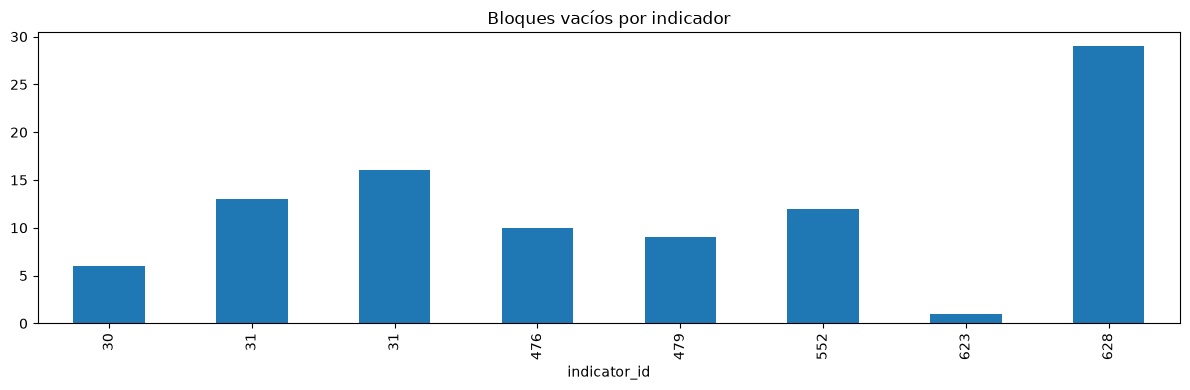

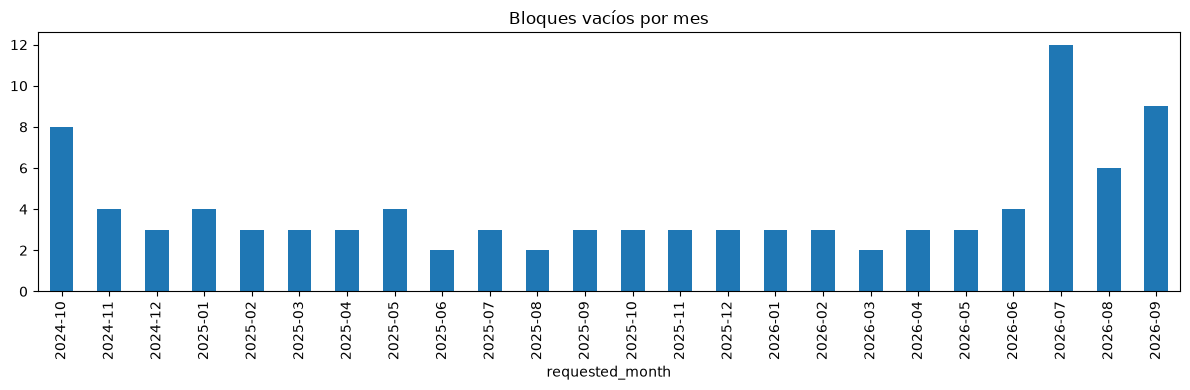

,indicator_id,indicator_name,frequency,empty_blocks,short_name,description
0,30,Generación programada PBF Importación Marruecos,Quince minutos,6,Importación Marruecos,"Es el programa de energía diario, con desglose..."
1,31,Generación programada PBF Importación Andorra,Hora,13,Importación Andorra,"Es el programa de energía diario, con desglose..."
2,31,Generación programada PBF Importación Andorra,Quince minutos,16,Importación Andorra,"Es el programa de energía diario, con desglose..."
3,476,Potencia disponible de generación Hulla sub-bi...,Hora,10,Hulla sub-bituminosa,"Calculada, para cada tipo de producción de gen..."
4,479,Potencia disponible de generación Gas Natural ...,Hora,9,Gas Natural,"Calculada, para cada tipo de producción de gen..."
5,552,Generación T.Real solar,Cinco minutos,12,Solar,Generación medida en tiempo real del tipo de p...
6,623,Índice de llenado medio semanal de almacenamie...,Semana,1,Llenado medio semanal hidráulico,Índice de llenado medio semanal agregado de to...
7,628,Precio Reserva de potencia adicional a subir,Hora,29,Reserva de potencia adicional a subir,La contratación y gestión de reserva de potenc...


In [19]:
empty_catalog_comparison = empty_by_indicator.merge(
    selected_catalog[["indicator_id", "indicator_name", "short_name", "description"]],
    on=["indicator_id", "indicator_name"],
    how="left",
    suffixes=("_raw", "_catalog"),
)

try:
    import matplotlib.pyplot as plt

    if not empty_by_indicator.empty:
        empty_by_indicator.plot.bar(
            x="indicator_id", y="empty_blocks", legend=False,
            title="Bloques vacíos por indicador", figsize=(12, 4),
        )
        plt.tight_layout()
        plt.show()
    if not empty_by_month.empty:
        empty_by_month.plot.bar(
            x="requested_month", y="empty_blocks", legend=False,
            title="Bloques vacíos por mes", figsize=(12, 4),
        )
        plt.tight_layout()
        plt.show()
except ImportError:
    print("matplotlib no está instalado; se conservan las tablas de diagnóstico.")

empty_catalog_comparison

## 5. Aplanado de valores ESIOS

Cada valor conserva el indicador, ámbito geográfico, metadatos de publicación, rango solicitado y archivo raw de origen.

In [20]:
value_rows = []
for record in block_records:
    if record["status"] != "valid":
        continue
    indicator = record["payload"]["indicator"]
    for value in indicator["values"]:
        if not isinstance(value, dict):
            continue
        value_rows.append({
            "indicator_id": record["indicator_id"],
            "indicator_name": indicator.get("name"),
            "short_name": indicator.get("short_name"),
            "unit": record["unit"],
            "frequency": record["frequency"],
            "fecha_inicio": value.get("datetime_utc") or value.get("datetime"),
            "fecha_fin": value.get("datetime_end") or value.get("end_datetime"),
            "valor": value.get("value"),
            "geo_id": value.get("geo_id"),
            "geo_name": value.get("geo_name"),
            "requested_start": record["requested_start"],
            "requested_end": record["requested_end"],
            "source_file": record["source_file"],
        })

values = pd.DataFrame(value_rows)
if values.empty:
    raise ValueError("No se encontraron valores válidos en los bloques raw.")
print(f"Valores aplanados: {len(values):,}")

Valores aplanados: 3,984,853


## 6. Normalización de fechas, valores y metadatos

Las fechas se normalizan a UTC y los valores no convertibles pasan a nulo. Los valores ausentes nunca se sustituyen por cero.

In [21]:
values["fecha_inicio"] = pd.to_datetime(values["fecha_inicio"], utc=True, errors="coerce")
values["fecha_fin"] = pd.to_datetime(values["fecha_fin"], utc=True, errors="coerce")
values["valor"] = pd.to_numeric(values["valor"], errors="coerce")
values["indicator_id"] = pd.to_numeric(values["indicator_id"], errors="coerce").astype("Int64")
values["geo_id"] = pd.to_numeric(values["geo_id"], errors="coerce").astype("Int64")
values["datetime_local"] = values["fecha_inicio"].dt.tz_convert("Europe/Madrid")
values["fecha_inicio_fuera_ventana"] = (values["fecha_inicio"] < START_DATE) | (values["fecha_inicio"] > END_DATE)
normalization_report = {
    "invalid_timestamps": int(values["fecha_inicio"].isna().sum()),
    "invalid_numeric_values": int(values["valor"].isna().sum()),
    "missing_geo_id": int(values["geo_id"].isna().sum()),
    "missing_fecha_fin": int(values["fecha_fin"].isna().sum()),
}
values.head()

,indicator_id,indicator_name,short_name,unit,frequency,fecha_inicio,fecha_fin,valor,geo_id,geo_name,requested_start,requested_end,source_file,datetime_local,fecha_inicio_fuera_ventana
0,1297,Generación T.Real Cogeneración y resto,Cogeneración y resto,Potencia,Cinco minutos,2024-10-01 00:00:00+00:00,NaT,2041.0,8741,Península,2024-10-01,2024-10-30,data\raw\esios\indicadores\1297\indicador_1297...,2024-10-01 02:00:00+02:00,False
1,1297,Generación T.Real Cogeneración y resto,Cogeneración y resto,Potencia,Cinco minutos,2024-10-01 00:05:00+00:00,NaT,2043.0,8741,Península,2024-10-01,2024-10-30,data\raw\esios\indicadores\1297\indicador_1297...,2024-10-01 02:05:00+02:00,False
2,1297,Generación T.Real Cogeneración y resto,Cogeneración y resto,Potencia,Cinco minutos,2024-10-01 00:10:00+00:00,NaT,2045.0,8741,Península,2024-10-01,2024-10-30,data\raw\esios\indicadores\1297\indicador_1297...,2024-10-01 02:10:00+02:00,False
3,1297,Generación T.Real Cogeneración y resto,Cogeneración y resto,Potencia,Cinco minutos,2024-10-01 00:15:00+00:00,NaT,2046.0,8741,Península,2024-10-01,2024-10-30,data\raw\esios\indicadores\1297\indicador_1297...,2024-10-01 02:15:00+02:00,False
4,1297,Generación T.Real Cogeneración y resto,Cogeneración y resto,Potencia,Cinco minutos,2024-10-01 00:20:00+00:00,NaT,2050.0,8741,Península,2024-10-01,2024-10-30,data\raw\esios\indicadores\1297\indicador_1297...,2024-10-01 02:20:00+02:00,False


## 7. Duplicados e intervalos temporales

In [22]:
key_columns = ["indicator_id", "fecha_inicio", "fecha_fin", "geo_id", "geo_name"]
duplicate_mask = values.duplicated(subset=key_columns, keep="last")
duplicate_rows = values.loc[duplicate_mask, key_columns + ["source_file"]].copy()
duplicates_removed = int(duplicate_mask.sum())

print(f"Duplicados detectados: {duplicates_removed}")
if duplicate_rows.empty:
    print("No se encontraron duplicados.")
else:
    print("Duplicados que se eliminarán (máximo 50):")
    print(duplicate_rows.head(50).to_string(index=False))

values = values.loc[~duplicate_mask].copy()
values = values.sort_values(["indicator_id", "fecha_inicio", "geo_id"], na_position="last").reset_index(drop=True)
print("\nPrimeros valores después de eliminar duplicados:")
print(values.head(20).to_string(index=False))

invalid_interval_mask = values["fecha_fin"].notna() & (values["fecha_fin"] < values["fecha_inicio"])
out_of_window = values["fecha_inicio"].notna() & ~values["fecha_inicio"].between(START_DATE, END_DATE)
interval_report = {
    "duplicates_removed": duplicates_removed,
    "invalid_intervals": int(invalid_interval_mask.sum()),
    "values_outside_configured_window": int(out_of_window.sum()),
    "timestamps_out_of_order_by_indicator": int(sum(
        not group["fecha_inicio"].dropna().is_monotonic_increasing
        for _, group in values.groupby("indicator_id")
    )),
}
interval_report

Duplicados detectados: 405759
Duplicados que se eliminarán (máximo 50):
 indicator_id              fecha_inicio fecha_fin  geo_id  geo_name                                                               source_file
         1297 2026-07-01 00:00:00+00:00       NaT    8741 Península data\raw\esios\indicadores\1297\indicador_1297_2026-06-23_2026-07-22.json
         1297 2026-07-01 00:05:00+00:00       NaT    8741 Península data\raw\esios\indicadores\1297\indicador_1297_2026-06-23_2026-07-22.json
         1297 2026-07-01 00:10:00+00:00       NaT    8741 Península data\raw\esios\indicadores\1297\indicador_1297_2026-06-23_2026-07-22.json
         1297 2026-07-01 00:15:00+00:00       NaT    8741 Península data\raw\esios\indicadores\1297\indicador_1297_2026-06-23_2026-07-22.json
         1297 2026-07-01 00:20:00+00:00       NaT    8741 Península data\raw\esios\indicadores\1297\indicador_1297_2026-06-23_2026-07-22.json
         1297 2026-07-01 00:25:00+00:00       NaT    8741 Península data\raw

{'duplicates_removed': 405759,
 'invalid_intervals': 0,
 'values_outside_configured_window': 0,
 'timestamps_out_of_order_by_indicator': 0}

## 8. Informe de calidad y cobertura

El informe diferencia ausencia de datos (`empty`) de corrupción (`malformed`/`unreadable`) y deja acciones recomendadas para revisar los 80 bloques vacíos.

In [23]:
status_counts = blocks["status"].value_counts().to_dict()
coverage = values.groupby("indicator_id").agg(
    values=("valor", "size"),
    date_min=("fecha_inicio", "min"),
    date_max=("fecha_inicio", "max"),
    null_values=("valor", lambda series: int(series.isna().sum())),
).reset_index()
coverage["null_rate"] = coverage["null_values"] / coverage["values"]
coverage = coverage.merge(
    selected_catalog[["indicator_id", "indicator_name", "short_name"]],
    on="indicator_id",
    how="left",
)
null_by_indicator = coverage[coverage["null_values"] > 0].sort_values(
    ["null_rate", "null_values"], ascending=False
)
observations = []
if len(empty_detail):
    observations.append(
        f"Hay {len(empty_detail)} bloques vacíos; se conservan como ausencia de publicación, no como ceros."
    )
if not null_by_indicator.empty:
    top_null = null_by_indicator.iloc[0]
    observations.append(
        f"Mayor tasa de valores nulos: indicador {int(top_null['indicator_id'])} "
        f"({top_null['indicator_name']}), {int(top_null['null_values'])} de "
        f"{int(top_null['values'])} ({top_null['null_rate']:.2%})."
    )
if interval_report["duplicates_removed"]:
    observations.append(
        f"Se eliminaron {interval_report['duplicates_removed']} duplicados conservando la última aparición."
    )
if not observations:
    observations.append("No se detectaron observaciones relevantes en la cobertura normalizada.")

empty_causes = [
    "Si existen valores en meses posteriores, el vacío representa un hueco selectivo de cobertura y no datos futuros.",
    "Comparar los indicadores vacíos de julio con los que tienen valores en agosto y septiembre.",
    "Revisar si el hueco coincide con un límite de bloque, una frecuencia o una geografía concreta.",
    "Contrastar el indicador y su catálogo para detectar una interrupción o cambio de serie publicada.",
    "Si hay bloques malformados o ilegibles, revisar la respuesta y reintentar solo esos archivos.",
]
quality_report = {
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "configured_window": {"start": START_DATE.isoformat(), "end": END_DATE.isoformat()},
    "raw_files": int(len(blocks)),
    "blocks_by_status": {str(key): int(value) for key, value in status_counts.items()},
    "values_after_deduplication": int(len(values)),
    "indicators_with_data": sorted(map(int, coverage["indicator_id"].dropna().unique())),
    "indicators_with_all_blocks_empty": all_empty_indicators.to_dict(orient="records"),
    "observations": observations,
    "normalization": normalization_report,
    "intervals": interval_report,
    "null_values_by_indicator": null_by_indicator.to_dict(orient="records"),
    "empty_blocks": {
        "count": int(len(empty_detail)),
        "by_indicator": empty_by_indicator.to_dict(orient="records"),
        "by_month": empty_by_month.to_dict(orient="records"),
        "by_year": empty_by_year.to_dict(orient="records"),
        "possible_causes_and_actions": empty_causes,
    },
    "coverage": coverage.assign(
        date_min=coverage["date_min"].astype("string"),
        date_max=coverage["date_max"].astype("string"),
    ).to_dict(orient="records"),
}
print("Observaciones:")
for observation in observations:
    print(f"- {observation}")
print("\nIndicadores con valores nulos:")
print(null_by_indicator[["indicator_id", "indicator_name", "short_name", "values", "null_values", "null_rate"]].to_string(index=False))
print("\nResumen de bloques:")
print(json.dumps(quality_report["blocks_by_status"], indent=2, ensure_ascii=False))

Observaciones:
- Hay 96 bloques vacíos; se conservan como ausencia de publicación, no como ceros.
- Se eliminaron 405759 duplicados conservando la última aparición.

Indicadores con valores nulos:
Empty DataFrame
Columns: [indicator_id, indicator_name, short_name, values, null_values, null_rate]
Index: []

Resumen de bloques:
{
  "valid": 1090,
  "empty": 96
}


## 9. Guardar processed y diagnósticos

In [24]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

serializable_values = values.copy()
for column in serializable_values.columns:
    if pd.api.types.is_datetime64_any_dtype(serializable_values[column]):
        serializable_values[column] = serializable_values[column].astype("string")
serializable_values = serializable_values.astype(object).where(serializable_values.notna(), None)

values_path = OUT_DIR / "esios_valores.json"
quality_path = OUT_DIR / "calidad_esios.json"
empty_path = OUT_DIR / "bloques_vacios_esios.csv"
values_path.write_text(json.dumps(serializable_values.to_dict(orient="records"), ensure_ascii=False), encoding="utf-8")
quality_path.write_text(json.dumps(quality_report, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
empty_detail.to_csv(empty_path, index=False, encoding="utf-8-sig")

print(f"Valores: {values_path}")
print(f"Calidad: {quality_path}")
print(f"Vacíos: {empty_path}")

Valores: c:\Users\zhen.xiang\OneDrive - Accenture\Documents\SAT\Energy\odb-challenge-energy-optimizer\data\processed\esios\esios_valores.json
Calidad: c:\Users\zhen.xiang\OneDrive - Accenture\Documents\SAT\Energy\odb-challenge-energy-optimizer\data\processed\esios\calidad_esios.json
Vacíos: c:\Users\zhen.xiang\OneDrive - Accenture\Documents\SAT\Energy\odb-challenge-energy-optimizer\data\processed\esios\bloques_vacios_esios.csv


## 10. Comprobaciones automáticas

Los vacíos esperados no hacen fallar el pipeline, pero se conservan y generan advertencias. Los archivos corruptos, ilegibles, timestamps inválidos y claves duplicadas sí detienen la ejecución.

In [25]:
import warnings

required_columns = {
    "indicator_id", "fecha_inicio", "fecha_fin", "valor", "geo_id", "source_file"
}
missing_columns = sorted(required_columns - set(values.columns))
if missing_columns:
    raise AssertionError(f"Faltan columnas obligatorias: {missing_columns}")

if blocks["status"].isin(["malformed", "unreadable"]).any():
    bad_files = blocks.loc[blocks["status"].isin(["malformed", "unreadable"]), "source_file"].tolist()
    raise ValueError(f"Hay archivos raw corruptos o ilegibles: {bad_files[:10]}")
if normalization_report["invalid_timestamps"] or normalization_report["invalid_numeric_values"]:
    raise ValueError(f"Hay valores no normalizables: {normalization_report}")
if interval_report["invalid_intervals"]:
    raise ValueError(f"Hay intervalos inválidos: {interval_report}")
if values.duplicated(key_columns).any():
    raise AssertionError("La clave de valores no es única tras deduplicar")
if len(empty_detail) != int((blocks["status"] == "empty").sum()):
    raise AssertionError("No se conservaron todos los bloques vacíos en el diagnóstico")

indicators_without_data = sorted(set(INDICATOR_IDS) - set(values["indicator_id"].dropna().astype(int)))
if indicators_without_data:
    warnings.warn(
        f"Indicadores seleccionados sin valores: {indicators_without_data}. "
        "Revisar cobertura, granularidad, geografía e ID en el catálogo.",
        stacklevel=2,
    )

assert values["indicator_id"].notna().all()
assert values["fecha_inicio"].notna().all()
assert values_path.exists() and quality_path.exists() and empty_path.exists()
print("Comprobaciones automáticas: OK")

Comprobaciones automáticas: OK


c:\Users\zhen.xiang\OneDrive - Accenture\Documents\SAT\Energy\.venv\Lib\site-packages\IPython\core\interactiveshell.py:3823: UserWarning: Indicadores seleccionados sin valores: [31, 628]. Revisar cobertura, granularidad, geografía e ID en el catálogo.
  exec(code_obj, self.user_global_ns, self.user_ns)
